In [17]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from random import shuffle
import random
random.seed(42)

In [18]:
r_scape = pickle.load(open("data/eval_rscape.pickle", "rb"))
phylo_score = pickle.load(open("data/eval_phyloscore.pickle", "rb"))
datasets = list(map(str.strip, open("3d.txt", "r")))

In [19]:
r_scape_no_cor = { key: value for key, value in r_scape.items() if not (key[1].endswith("p")  or key[1].endswith("a")) }
phylo_score_no_cor = { key: value for key, value in phylo_score.items() if key[4] == 'None' }

In [20]:
def extract_hyperparameters(dict):
    keys = [k[1:] for k in dict.keys()]
    return set(keys)
def best_hyper(dict, train_set):
    best_score = -1
    best_hyperparameters = None
    for hyper in extract_hyperparameters(dict):
        score = 0
        for dataset in train_set:
            score += dict[(dataset, *hyper)][1]
        
        if score > best_score:
            best_score = score
            best_hyperparameters = hyper
    return best_hyperparameters

In [21]:
print(best_hyper(phylo_score, datasets))
print(best_hyper(r_scape, datasets))
print(best_hyper(phylo_score_no_cor, datasets))
print(best_hyper(r_scape_no_cor, datasets))

('0.5', '0.01', 'optdiff', 'APC')
('GTp',)
('0.25', '0.0', 'optdiff', 'None')
('GT',)


In [31]:
def cross_validation(data, per_dataset_results : dict, selected_hyper : set, splits=5):
    local_datasets = list(datasets)
    # shuffle the datasets
    shuffle(local_datasets)

    #split in splits folds
    numpy = np.array(local_datasets)
    folds = np.array_split(numpy, splits)

    results = []
    for i in range(splits):
        test = set(folds[i])
        train = set(numpy) - test

        best_hyperparameters = best_hyper(data, train)
        selected_hyper.add(best_hyperparameters)
        for dataset in test:
            results.append(data[(dataset, *best_hyperparameters)][1])
            if dataset not in per_dataset_results:
                per_dataset_results[dataset] = []
            per_dataset_results[dataset].append(data[(dataset, *best_hyperparameters)][1])
        
    return np.mean(results)

In [32]:
rscape_per_dataset = {}
rscape_hyperparameters = set()
phylo_score_per_dataset = {}
phylo_score_hyperparameters = set()
results_rscape = [cross_validation(r_scape, rscape_per_dataset, rscape_hyperparameters) for _ in range(1000)]
results_phyloscore = [cross_validation(phylo_score, phylo_score_per_dataset, phylo_score_hyperparameters) for _ in range(1000)]

In [33]:
rscape_per_dataset_no_cor = {}
rscape_hyperparameters_no_cor = set()
phylo_score_per_dataset_no_cor = {}
phylo_score_hyperparameters_no_cor = set()
results_rscape_no_cor = [cross_validation(r_scape_no_cor, rscape_per_dataset_no_cor, rscape_hyperparameters_no_cor) for _ in range(1000)]
results_phyloscore_no_cor = [cross_validation(phylo_score_no_cor, phylo_score_per_dataset_no_cor, phylo_score_hyperparameters_no_cor) for _ in range(1000)]

In [35]:
for hyper in phylo_score_hyperparameters:
    print(hyper, np.mean([phylo_score[(dataset, *hyper)][1] for dataset in datasets]))

print("No correction")
for hyper in phylo_score_hyperparameters_no_cor:
    print(hyper, np.mean([phylo_score_no_cor[(dataset, *hyper)][1] for dataset in datasets]))

('0.5', '0.01', 'optdiff', 'ASC') 0.7146693245978758
('0.5', '0.1', 'optdiff', 'ASC') 0.7144880704922469
('0.5', '0.0', 'optdiff', 'ASC') 0.7144999201961562
('1.0', '1.0', 'optdiff', 'APC') 0.712394760877221
('1.0', '0.01', 'optdiff', 'APC') 0.7128661672802584
('1.0', '0.0', 'optdiff', 'APC') 0.7127192504916801
('1.0', '0.01', 'optdiff', 'ASC') 0.7136479175578238
('1.0', '0.0', 'optdiff', 'ASC') 0.7133380598356188
('0.5', '0.01', 'optdiff', 'APC') 0.7147547542939079
('0.5', '0.1', 'optdiff', 'APC') 0.7146611305435817
('0.5', '0.0', 'optdiff', 'APC') 0.7144816947132968
No correction
('0.5', '0.01', 'optdiff', 'None') 0.7031562803177177
('0.5', '0.0', 'optdiff', 'None') 0.7032408683499352
('0.25', '0.01', 'optdiff', 'None') 0.7037857916106859
('0.5', '0.1', 'optdiff', 'None') 0.7033137369598693
('0.25', '0.0', 'optdiff', 'None') 0.7040068935457482


In [36]:
for hyper in rscape_hyperparameters:
    print(hyper, np.mean([r_scape[(dataset, *hyper)][1] for dataset in datasets]))
print("No correction")
for hyper in rscape_hyperparameters_no_cor:
    print(hyper, np.mean([r_scape_no_cor[(dataset, *hyper)][1] for dataset in datasets]))

('GTp',) 0.6789628378088932
No correction
('GT',) 0.6133778310400462
('CHI',) 0.6087287911239722


In [37]:
def scatter_compare_with_diagonal(dict1, dict2, label1='Dataset 1', label2='Dataset 2', figsize=(8, 8), no_corrections=False):
   
    # Get common categories
    common_keys = sorted(set(dict1.keys()) & set(dict2.keys()))
    
    if not common_keys:
        raise ValueError("Dictionaries have no common keys")
    
    medians1 = []
    medians2 = []
    errors1 = []
    errors2 = []
    
    for key in common_keys:
        data1 = dict1[key]
        data2 = dict2[key]
        
        median1 = np.median(data1)
        median2 = np.median(data2)
        medians1.append(median1)
        medians2.append(median2)
        
        errors1.append([np.abs(np.median(data1) - np.min(data1)), np.abs(np.max(data1) - np.median(data1))])
        errors2.append([np.abs(np.median(data2) - np.min(data2)), np.abs(np.max(data2) - np.median(data2))])
    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    
    # Add diagonal line (y=x)
    min_val = 0
    max_val = 1
    ax.plot([min_val, max_val], 
            [min_val, max_val], 
            'k--', alpha=0.5)
    
    # Add error bars (horizontal and vertical)
    if not no_corrections:
        ax.errorbar(medians1, medians2,
                   yerr=np.array(errors2).T,
                   fmt='o', capsize=3, capthick=1, elinewidth=1,
                   color='blue', alpha=0.7, markersize=2,
                   label=f'{label1} vs {label2}')
    else:
        ax.errorbar(medians1, medians2,
                   yerr=np.array(errors2).T,
                   xerr=np.array(errors1).T,
                   fmt='x', capsize=0, capthick=1, elinewidth=1,
                   color='blue', alpha=0.1, markersize=0, label=f'Crossvalidation uncertainty')
        ax.scatter(medians1, medians2,
                   color='blue', alpha=0.7, s=4,
                   label=f'{label1} vs {label2} medians')
        
    
    # Customize plot
    ax.set_xlabel(f'{label1} (Average Precision)', fontsize=12)
    ax.set_ylabel(f'{label2} (Average Precision)', fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')
    ax.set_aspect('equal')
    
    plt.tight_layout()
    return fig, ax

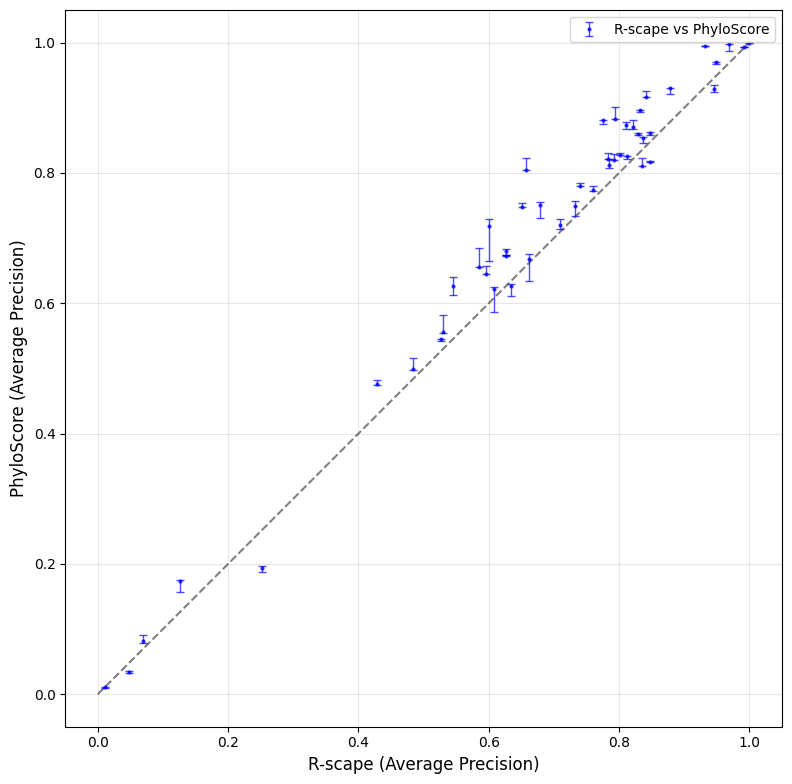

In [38]:
fig, _ =scatter_compare_with_diagonal(rscape_per_dataset, phylo_score_per_dataset, label1='R-scape', label2='PhyloScore')
fig.savefig("cross_validation_scatter.pdf")

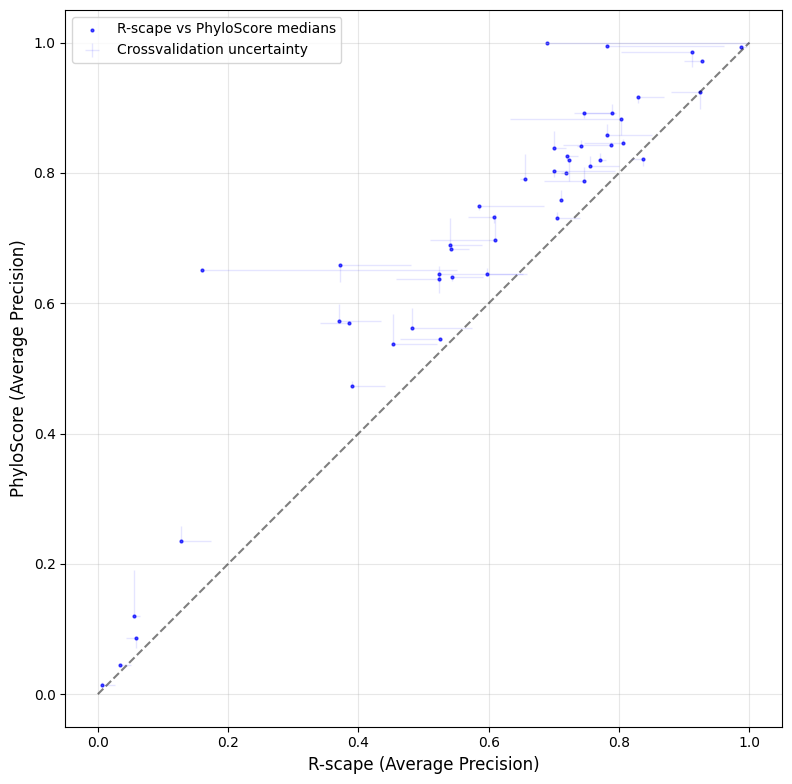

In [39]:
fig, _ =scatter_compare_with_diagonal(rscape_per_dataset_no_cor, phylo_score_per_dataset_no_cor, label1='R-scape', label2='PhyloScore', no_corrections=True)
fig.savefig("cross_validation_scatter_no_corrections.pdf")

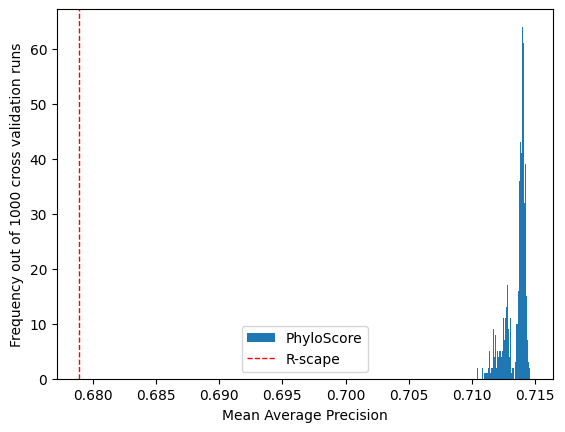

In [40]:
plt.hist(results_phyloscore, bins=100, label='PhyloScore')
plt.axvline(np.mean(results_rscape), color='red', linestyle='dashed', linewidth=1, label='R-scape')
plt.xlabel('Mean Average Precision')
plt.ylabel('Frequency out of 1000 cross validation runs')
plt.legend()
plt.savefig("cross_validation_results.pdf")

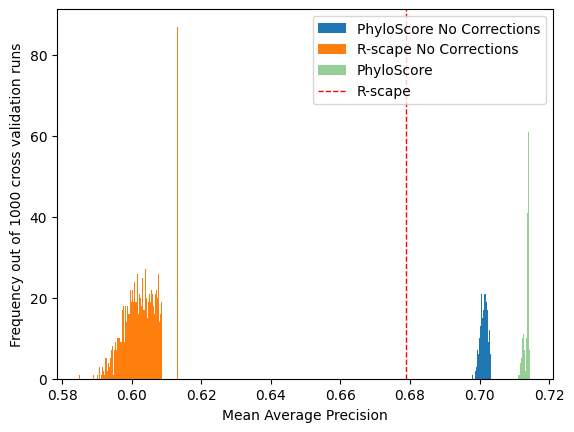

In [43]:
plt.hist(results_phyloscore_no_cor, bins=100, label='PhyloScore No Corrections')
plt.hist(results_rscape_no_cor, bins=100, label='R-scape No Corrections')
plt.hist(results_phyloscore, bins=100, label='PhyloScore', alpha=0.5)
plt.axvline(np.mean(results_rscape), color='red', linestyle='dashed', linewidth=1, label='R-scape')
plt.xlabel('Mean Average Precision')
plt.ylabel('Frequency out of 1000 cross validation runs')
plt.legend()
plt.savefig("cross_validation_results_no_corrections.pdf")

In [44]:
all_hyper = extract_hyperparameters(phylo_score)

In [45]:
def plot_variation_per_hyperparameter(phylo_score):
    all_hyper = extract_hyperparameters(phylo_score)
    num_types = len(next(iter(all_hyper)))
    
    # Create a 2x2 grid of subplots
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    # Flatten axes for easy indexing (optional)
    axes = axes.flatten()
    
    str_types = ["lambda", "lambda_MI", "score type", "correction type"]
    
    for type in range(num_types):
        hyperparameters = sorted(list(set(h[type] for h in all_hyper)), key=lambda x: float(x) if x.replace('.', '', 1).isdigit() else x)
        max_values = []
        for hyper in hyperparameters:
            values = [np.array([phylo_score[(dataset, *h)][1] for dataset in datasets]).mean() for h in all_hyper if h[type] == hyper]
            max = np.max(values)
            max_values.append(max)
            print(f"Type {type}, Hyperparameter {hyper}: Max AP = {max:.4f}")
        axes[type].bar(list(hyperparameters), max_values)
        axes[type].set_ylabel('Maximum Average Precision')
        axes[type].set_ylim(0.65, 0.72)
        axes[type].set_title(f'Effect of {str_types[type]}')
        axes[type].set_xticklabels(hyperparameters, rotation=90)
    plt.tight_layout()
    plt.savefig("hyperparameter_variation.pdf")
    plt.show()
    

Type 0, Hyperparameter 0.05: Max AP = 0.6906
Type 0, Hyperparameter 0.1: Max AP = 0.6984
Type 0, Hyperparameter 0.25: Max AP = 0.7090
Type 0, Hyperparameter 0.5: Max AP = 0.7148
Type 0, Hyperparameter 1.0: Max AP = 0.7136
Type 0, Hyperparameter 2.5: Max AP = 0.7127
Type 0, Hyperparameter 5.0: Max AP = 0.7085
Type 1, Hyperparameter 0.0: Max AP = 0.7145
Type 1, Hyperparameter 0.01: Max AP = 0.7148
Type 1, Hyperparameter 0.1: Max AP = 0.7147
Type 1, Hyperparameter 1.0: Max AP = 0.7133
Type 1, Hyperparameter 10.0: Max AP = 0.7089
Type 2, Hyperparameter lldiff: Max AP = 0.7127
Type 2, Hyperparameter optdiff: Max AP = 0.7148
Type 3, Hyperparameter APC: Max AP = 0.7148
Type 3, Hyperparameter ASC: Max AP = 0.7147
Type 3, Hyperparameter None: Max AP = 0.7040


/tmp/ipykernel_3758709/1011431671.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)
/tmp/ipykernel_3758709/1011431671.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)
/tmp/ipykernel_3758709/1011431671.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)
/tmp/ipykernel_3758709/1011431671.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[type].set_xticklabels(hyperparameters, rotation=90)


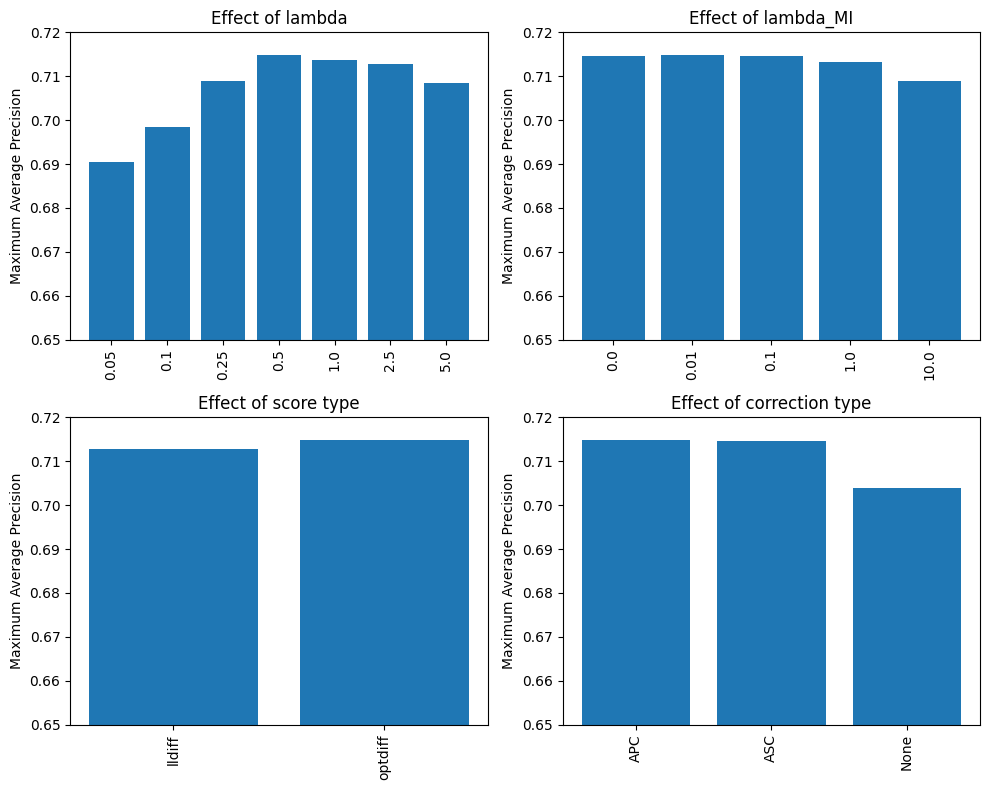

In [46]:
plot_variation_per_hyperparameter(phylo_score)